# Prática 3 — LSTM: previsão de nascimentos mensais

**Duração:** 30 minutos · **Público:** iniciantes · **Ambiente:** Google Colab (CPU)

**Pergunta de pesquisa didática:** É possível utilizar os doze meses anteriores para prever o número de nascimentos do mês seguinte?

**Objetivos:** compreender séries temporais, janelas de observação, divisão cronológica entre treino e teste, estrutura de uma rede LSTM e comparação com uma referência simples.

**Base:** 120 valores mensais sintéticos, de janeiro de 2015 a dezembro de 2024, construídos com tendência, sazonalidade e ruído. Não são dados oficiais. Não utilize os resultados para inferir tendências demográficas reais.

**Como usar:** execute as células em ordem; leia as explicações e compare as saídas antes de alterar parâmetros. A LSTM pode apresentar desempenho inferior ao método simples, e isso faz parte da interpretação científica.

## Passo 1 — Importar bibliotecas

Utilizaremos NumPy e pandas para organizar a série mensal, Matplotlib para os gráficos, scikit-learn para normalização e avaliação, e TensorFlow/Keras para construir a LSTM.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error
from tensorflow import keras

keras.utils.set_random_seed(42)

I0000 00:00:1794246254.697827    4153 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794246254.699151    4153 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794246254.739679    4153 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794246255.911889    4153 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

## Passo 2 — Criar uma série temporal sintética

Geraremos 120 meses (10 anos) de nascimentos fictícios com tendência, sazonalidade anual e ruído. Esta série não é uma base do SINASC ou do IBGE.

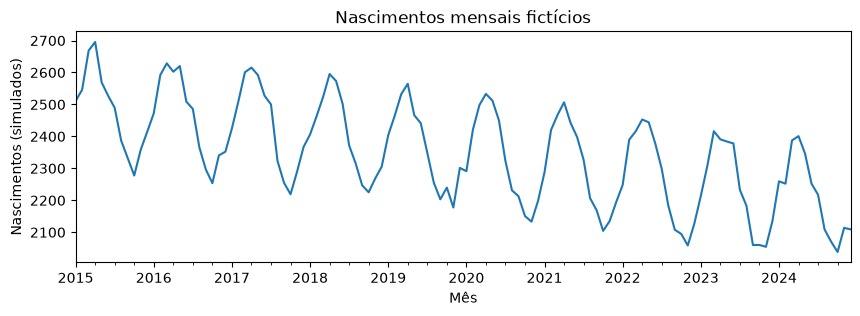

In [2]:
rng = np.random.default_rng(42)
datas = pd.date_range("2015-01-01", periods=120, freq="MS")
mes = np.arange(120)

nascimentos = (
    2500
    - 2.5 * mes
    + 170 * np.sin(2 * np.pi * mes / 12)
    + rng.normal(0, 35, 120)
)

serie = pd.Series(nascimentos, index=datas, name="nascimentos")

serie.plot(figsize=(10, 3), title="Nascimentos mensais fictícios")
plt.ylabel("Nascimentos (simulados)")
plt.xlabel("Mês")
plt.show()

## Passo 3 — Preparar janelas de 12 meses

Usaremos os primeiros 96 meses para treinamento e os 24 últimos para teste. A normalização é ajustada apenas no treino. Para prever um mês, o modelo receberá os 12 meses anteriores.

In [3]:
n_treino = 96
janela = 12

valores = serie.to_numpy().reshape(-1, 1)

escala = MinMaxScaler()
escala.fit(valores[:n_treino])
normalizados = escala.transform(valores)

X, y, indices = [], [], []
for i in range(janela, len(normalizados)):
    X.append(normalizados[i-janela:i])
    y.append(normalizados[i, 0])
    indices.append(i)

X = np.array(X)
y = np.array(y)
indices = np.array(indices)

X_treino, y_treino = X[indices < n_treino], y[indices < n_treino]
X_teste, y_teste = X[indices >= n_treino], y[indices >= n_treino]

print("Treino:", X_treino.shape, "Teste:", X_teste.shape)
print("Formato: (exemplos, meses anteriores, variáveis)")

Treino: (84, 12, 1) Teste: (24, 12, 1)
Formato: (exemplos, meses anteriores, variáveis)


## Passo 4 — Treinar uma LSTM

A camada LSTM aprende relações na sequência de 12 observações anteriores. A camada final retorna uma previsão numérica para o mês seguinte.

E0000 00:00:1794246256.236804    4153 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


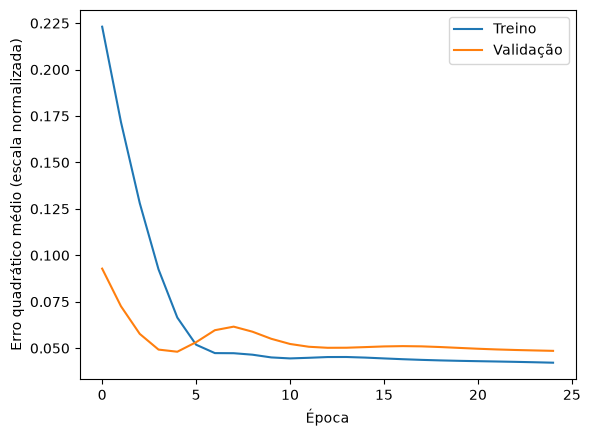

In [4]:
modelo = keras.Sequential([
    keras.Input(shape=(janela, 1)),
    keras.layers.LSTM(16),
    keras.layers.Dense(1)
])

modelo.compile(optimizer="adam", loss="mse")

historico = modelo.fit(
    X_treino, y_treino,
    epochs=25,
    batch_size=16,
    validation_split=0.15,
    shuffle=False,
    verbose=0
)

plt.plot(historico.history["loss"], label="Treino")
plt.plot(historico.history["val_loss"], label="Validação")
plt.xlabel("Época")
plt.ylabel("Erro quadrático médio (escala normalizada)")
plt.legend()
plt.show()

## Passo 5 — Avaliar e comparar com uma previsão simples

Vamos comparar a LSTM com o método sazonal ingênuo: prever o mesmo valor observado 12 meses antes. No teste, utilizamos apenas observações históricas para prever cada mês; não fazemos uma projeção recursiva de 24 meses.

In [5]:
previstas = modelo.predict(X_teste, verbose=0)
previstas = escala.inverse_transform(previstas).ravel()

reais = valores[indices >= n_treino, 0]
referencia = valores[indices[indices >= n_treino] - 12, 0]

erro_lstm = mean_absolute_error(reais, previstas)
erro_referencia = mean_absolute_error(reais, referencia)

print(f"MAE da LSTM: {erro_lstm:.1f} nascimentos")
print(f"MAE sazonal ingênuo: {erro_referencia:.1f} nascimentos")

datas_teste = serie.index[indices >= n_treino]
plt.figure(figsize=(10, 4))
plt.plot(datas_teste, reais, label="Observado")
plt.plot(datas_teste, previstas, label="LSTM")
plt.plot(datas_teste, referencia, "--", label="Mesmo mês do ano anterior")
plt.title("Comparação das previsões em 24 meses de teste")
plt.ylabel("Nascimentos (simulados)")
plt.xlabel("Mês")
plt.legend()
plt.show()

IndexError: boolean index did not match indexed array along dimension 0; dimension is 120 but corresponding boolean dimension is 108

## Agora é sua vez

1. Mude a janela de **12** para **6** meses. O erro da LSTM no teste muda?
2. Experimente **10** e **40** épocas. O modelo sempre melhora?
3. Compare com o método de repetir o valor de **12 meses antes**. Qual método tem menor MAE?

**Interpretação:** um erro menor em dados sintéticos não garante qualidade preditiva em dados reais. A previsão é para um mês à frente, utilizando os 12 valores históricos observados; não se trata de projetar 24 meses futuros sem observações intermediárias.

## Cuidados antes de usar dados reais

Verifique tendências, mudanças de cobertura e qualidade dos registros, possíveis rupturas, sazonalidade e adequada separação temporal. Uma LSTM não é necessariamente superior a métodos estatísticos tradicionais ou a referências sazonais simples.